In [2]:
import pandas as pd 
from sklearn.model_selection import train_test_split
import torch
import numpy as np
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import torchmetrics
import matplotlib.pyplot as plt
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


## Processing Data

In [3]:
df = pd.read_csv("EngineFaultDB_Final.csv")
X = df.drop(['Fault'], axis=1).values
y = df['Fault'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
df.head()   

,Fault,MAP,TPS,Force,Power,RPM,Consumption L/H,Consumption L/100KM,Speed,CO,HC,CO2,O2,Lambda,AFR
0,0,3.549,1.889,7.428,5.227,1192.769,3.057,11.720,24.901,0.460,196.089,14.356,1.080,1.047,15.385
1,0,3.559,1.899,7.646,5.327,1145.191,2.914,11.276,25.030,0.478,196.283,14.492,1.107,1.083,15.926
2,0,3.539,1.899,7.578,5.100,1208.505,2.976,11.926,24.213,0.464,200.367,14.443,1.099,1.072,15.754
3,0,3.519,1.889,7.371,5.255,1164.127,2.908,11.786,24.407,0.471,195.345,13.853,1.076,1.006,14.787
4,0,3.549,1.879,7.405,5.177,1172.032,2.898,12.169,24.875,0.468,194.979,13.752,1.060,0.984,14.470


In [31]:
'''
We also need to define feature configurations to be used in our experiments
Reference for features:
[MAP, TPS, Force, Power, RPM, Consumption L/H, Consumption L/100KM, Speed, CO, HC, CO2, O2, Lambda, AFR]   

CA: [MAP, TPS, Force, Power, RPM] 
CB: [MAP, RPM, O2, Lambda, AFR] 
CC: [CO, HC, CO2, O2, Lambda]
CD = [MAP, TPS, RPM, O2, Lambda, AFR, CO2]

C1: [MAP, TPS, RPM, O2, Lambda]
C2: [MAP, TPS, RPM, CO2, AFR]
C3: [MAP, RPM, CO2, O2, AFR]

C4: [TPS, RPM, CO2, O2, Lambda, AFR]

'''

C0 = [1,1,1,1,1,1,1,1,1,1,1,1,1,1] # Used for control experiments, C0 C0 

C1  = [1,1,1,0,1,0,0,0,0,0,0,1,0,0]  # [MAP, TPS, Force, RPM, O2]
C2  = [1,1,0,1,1,0,0,0,0,0,1,0,0,0]  # [MAP, TPS, Power, RPM, CO2]
C3  = [1,0,0,0,1,0,0,0,0,0,1,1,0,1]  # [MAP, RPM, CO2, O2, AFR]
C4  = [0,0,1,1,1,0,0,1,0,0,0,0,1,0]  # [Force, Power, RPM, Speed, Lambda]

C5  = [1,0,1,0,1,1,0,0,0,0,0,1,0,0]  # [MAP, Force, RPM, Consumption L/H, O2]
C6  = [0,1,0,1,1,0,1,0,0,0,0,0,0,1]  # [TPS, Power, RPM, Consumption L/100KM, AFR]
C7  = [0,0,1,1,0,0,0,1,1,0,1,0,0,0]  # [Force, Power, Speed, CO, CO2]
C8  = [1,0,0,0,1,1,0,0,0,1,0,0,1,0]  # [MAP, RPM, Consumption L/H, HC, Lambda]

C9  = [0,1,1,0,0,0,1,1,0,0,1,0,0,0]  # [TPS, Force, Consumption L/100KM, Speed, CO2]
C10 = [1,0,0,1,0,1,0,0,1,0,0,0,0,1]  # [MAP, Power, Consumption L/H, CO, AFR]
C11 = [0,1,0,0,1,0,0,1,0,1,0,0,1,0]  # [TPS, RPM, Speed, HC, Lambda]
C12 = [1,0,1,0,0,0,1,0,0,1,1,0,0,0]  # [MAP, Force, Consumption L/100KM, HC, CO2]

C13 = [0,0,1,1,1,0,0,0,1,0,0,0,0,1]  # [Force, Power, RPM, CO, AFR]
C14 = [1,1,0,0,0,1,0,1,0,0,0,1,0,0]  # [MAP, TPS, Consumption L/H, Speed, O2]
C15 = [0,0,0,1,1,1,0,0,0,1,1,0,0,0]  # [Power, RPM, Consumption L/H, HC, CO2]
C16 = [1,0,1,0,1,0,0,0,0,0,0,0,1,1]  # [MAP, Force, RPM, Lambda, AFR]


config_pairs = [
    (C1, C2),
    (C1, C4),
    (C2, C3),
    (C2, C7),
    (C3, C8),
    (C4, C9),
    (C5, C6),
    (C6, C10),
    (C7, C11),
    (C8, C14),
]

In [6]:
def jaccard_similarity(A, B):
    A = np.asarray(A, dtype=bool)
    B = np.asarray(B, dtype=bool)
    intersection = np.logical_and(A, B).sum()
    union = np.logical_or(A, B).sum()
    return intersection / union if union != 0 else 0.0 

In [16]:
jaccard_similarity(C4, C3) 

np.float64(0.6666666666666666)

In [18]:
def create_dataloaders(X_train, X_test, y_train, y_test, train_config, test_config, batch_size=64, use_mask=True):
    X_train = X_train.copy()
    X_test = X_test.copy()

    train_config = np.asarray(train_config, dtype=bool)
    test_config = np.asarray(test_config, dtype=bool)

    X_train[:, ~train_config] = 0.0
    X_test[:, ~test_config] = 0.0

    train_mask = np.tile(
        train_config.astype(np.float32),
        (len(X_train), 1)
    )

    test_mask = np.tile(
        test_config.astype(np.float32),
        (len(X_test), 1)
    )

    # Optionally give the model explicit information
    # about which features are available
    if use_mask:
        X_train = np.concatenate([X_train, train_mask], axis=1)
        X_test = np.concatenate([X_test, test_mask], axis=1)

    # Convert to tensors
    X_train = torch.tensor(X_train, dtype=torch.float32)
    X_test = torch.tensor(X_test, dtype=torch.float32)

    y_train = torch.tensor(y_train, dtype=torch.long)
    y_test = torch.tensor(y_test, dtype=torch.long)

    # Create datasets
    train_dataset = TensorDataset(X_train, y_train)
    test_dataset = TensorDataset(X_test, y_test)

    # Create loaders
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    return train_loader, test_loader

In [19]:
train_loader, test_loader = create_dataloaders(X_train, X_test, y_train, y_test, C0, C1, batch_size=64, use_mask=True)

## Experiment 0: Logistic Regression

In [39]:
class LogisticRegressionPytorch(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(LogisticRegressionPytorch, self).__init__()
        self.linear = nn.Linear(input_dim, output_dim)
    def forward(self, x):
        return self.linear(x)

def train_logistic_regression(train_loader, test_loader, model, criterion, optimizer, EPOCHS, checkpoint_path):
    best_loss = float('inf')
    best_accuracy = 0.0
    best_f1_score = 0.0
    train_losses = []
    val_losses = []
    accuracies = []
    f1_scores = [] 
    for epochs in range(EPOCHS):
        # Training loop
        model.train()
        for batch_idx, (data, target) in enumerate(train_loader):
            data = data.to(device)
            target = target.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()
        train_losses.append(loss.detach().cpu().numpy())
        
        # Evaluation
        model.eval()
        all_preds = []
        all_targets = []
        with torch.no_grad():
            for data, target in test_loader:
                data = data.to(device)
                target = target.to(device)
                output = model(data)
                preds = torch.argmax(output, dim=1)
                val_loss = criterion(output, target)
                all_preds.extend(preds.cpu().numpy())
                all_targets.extend(target.cpu().numpy())
        if val_loss.item() < best_loss:
            best_loss = val_loss.item()
            best_accuracy = accuracy_score(all_targets, all_preds)
            multiclass_f1 = torchmetrics.classification.MulticlassF1Score(4, average='macro')
            best_f1_score = multiclass_f1(torch.tensor(all_preds), torch.tensor(all_targets)).item()
            torch.save(model.state_dict(), checkpoint_path)  # Save the best model
            print(f"Best model saved with validation loss: {best_loss:.4f}")
        accuracy = accuracy_score(all_targets, all_preds)
        multiclass_f1 = torchmetrics.classification.MulticlassF1Score(4, average='macro')
        f1_score = multiclass_f1(torch.tensor(all_preds), torch.tensor(all_targets)).item()
        val_losses.append(val_loss)
        accuracies.append(accuracy)
        f1_scores.append(f1_score)
        print(f'Epoch {epochs+1}/{EPOCHS}, Accuracy: {accuracy:.4f}, F1-Score: {f1_score:.4f}')  
    results = {"train_losses": train_losses,
                "val_losses": val_losses,
                "accuracies": accuracies,
                "f1_scores": f1_scores}
    return results, best_accuracy, best_f1_score

In [ ]:
INPUT_DIM = X_train.shape[1] + len(C0)  # Adjust for mask
OUTPUT_DIM = len(np.unique(y_train))
BATCH_SIZE = 64
LEARNING_RATE=0.01
EPOCHS=10

model_0 = LogisticRegressionPytorch(INPUT_DIM, OUTPUT_DIM).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_0.parameters(), lr=LEARNING_RATE)

train_loader, test_loader = create_dataloaders(X_train, X_test, y_train, y_test, C0, C0) 
results_0_C0_C0, best_acc, best_f1 = train_logistic_regression(train_loader, test_loader, model_0, criterion, optimizer, EPOCHS, "best_model_0_C0_C0.pth")

Best model saved with validation loss: 12677.4824
Epoch 1/10, Accuracy: 0.3204, F1-Score: 0.2193
Best model saved with validation loss: 10457.0215
Epoch 2/10, Accuracy: 0.3113, F1-Score: 0.2529
Best model saved with validation loss: 8247.9062
Epoch 3/10, Accuracy: 0.2905, F1-Score: 0.1692
Epoch 4/10, Accuracy: 0.3064, F1-Score: 0.1884
Best model saved with validation loss: 6127.7588
Epoch 5/10, Accuracy: 0.3387, F1-Score: 0.2584
Epoch 6/10, Accuracy: 0.3212, F1-Score: 0.1989
Epoch 7/10, Accuracy: 0.3064, F1-Score: 0.1882
Epoch 8/10, Accuracy: 0.2976, F1-Score: 0.1731
Epoch 9/10, Accuracy: 0.2883, F1-Score: 0.1119
Epoch 10/10, Accuracy: 0.2883, F1-Score: 0.1119


In [ ]:
INPUT_DIM = X_train.shape[1] + len(C1)  # Adjust for mask
OUTPUT_DIM = len(np.unique(y_train))
BATCH_SIZE = 64
LEARNING_RATE=0.01
EPOCHS=25

model_0 = LogisticRegressionPytorch(INPUT_DIM, OUTPUT_DIM).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_0.parameters(), lr=LEARNING_RATE)

train_loader, test_loader = create_dataloaders(X_train, X_test, y_train, y_test, C1, C2)
results_0_C1_C2, best_acc, best_f1 = train_logistic_regression(train_loader, test_loader, model_0, criterion, optimizer, EPOCHS, "best_model_0_C1_C2.pth")


Best model saved with validation loss: 24977.2930
Epoch 1/25, Accuracy: 0.2696, F1-Score: 0.1062
Best model saved with validation loss: 8767.0859
Epoch 2/25, Accuracy: 0.1959, F1-Score: 0.0819
Epoch 3/25, Accuracy: 0.2883, F1-Score: 0.1119
Epoch 4/25, Accuracy: 0.2462, F1-Score: 0.0988
Best model saved with validation loss: 8286.6299
Epoch 5/25, Accuracy: 0.2462, F1-Score: 0.0988
Epoch 6/25, Accuracy: 0.2462, F1-Score: 0.0988
Epoch 7/25, Accuracy: 0.1959, F1-Score: 0.0819
Epoch 8/25, Accuracy: 0.2883, F1-Score: 0.1119
Epoch 9/25, Accuracy: 0.1959, F1-Score: 0.0819
Epoch 10/25, Accuracy: 0.2696, F1-Score: 0.1062
Epoch 11/25, Accuracy: 0.1959, F1-Score: 0.0819
Epoch 12/25, Accuracy: 0.2696, F1-Score: 0.1062
Epoch 13/25, Accuracy: 0.1959, F1-Score: 0.0819
Epoch 14/25, Accuracy: 0.2462, F1-Score: 0.0988
Epoch 15/25, Accuracy: 0.2696, F1-Score: 0.1062
Epoch 16/25, Accuracy: 0.2883, F1-Score: 0.1119
Epoch 17/25, Accuracy: 0.2696, F1-Score: 0.1062
Epoch 18/25, Accuracy: 0.2883, F1-Score: 0.11

In [41]:
accs = []
f1s = []
for i in range(len(config_pairs)):
    train_config, test_config = config_pairs[i]
    INPUT_DIM = X_train.shape[1] + len(train_config)  # Adjust for mask
    OUTPUT_DIM = len(np.unique(y_train))
    BATCH_SIZE = 64
    LEARNING_RATE=0.01
    EPOCHS=5

    model_0 = LogisticRegressionPytorch(INPUT_DIM, OUTPUT_DIM).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model_0.parameters(), lr=LEARNING_RATE)

    train_loader, test_loader = create_dataloaders(X_train, X_test, y_train, y_test, train_config, test_config)
    results, best_acc, best_f1_score = train_logistic_regression(train_loader, test_loader, model_0, criterion, optimizer, EPOCHS, f"best_model.pth")
    accs.append(best_acc)
    f1s.append(best_f1_score)

Best model saved with validation loss: 27025.0430
Epoch 1/5, Accuracy: 0.2696, F1-Score: 0.1062
Best model saved with validation loss: 16076.5586
Epoch 2/5, Accuracy: 0.2696, F1-Score: 0.1062
Epoch 3/5, Accuracy: 0.2883, F1-Score: 0.1119
Best model saved with validation loss: 11320.6367
Epoch 4/5, Accuracy: 0.2696, F1-Score: 0.1062
Epoch 5/5, Accuracy: 0.1959, F1-Score: 0.0819
Best model saved with validation loss: 22622.2012
Epoch 1/5, Accuracy: 0.2883, F1-Score: 0.1119
Epoch 2/5, Accuracy: 0.2883, F1-Score: 0.1119
Best model saved with validation loss: 18022.9785
Epoch 3/5, Accuracy: 0.2696, F1-Score: 0.1062
Best model saved with validation loss: 16880.1504
Epoch 4/5, Accuracy: 0.2883, F1-Score: 0.1119


KeyboardInterrupt: 

In [86]:
results_0_C0_C0_df = pd.DataFrame(results_0_C0_C0)
results_0_C0_C0_df.to_csv("results_0_C0_C0_df.csv")

In [80]:
train_loader, test_loader = create_dataloaders(X_train, X_test, y_train, y_test, C0, C1) 
results_0_C0_C1 = train_logistic_regression(train_loader, test_loader, model_0, criterion, optimizer, EPOCHS, "best_model_0_C0_C0.pth")

Best model saved with validation loss: 12827.9902
Epoch 1/10, Accuracy: 0.2132, F1-Score: 0.1111
Epoch 2/10, Accuracy: 0.2132, F1-Score: 0.1111
Epoch 3/10, Accuracy: 0.2132, F1-Score: 0.1114
Epoch 4/10, Accuracy: 0.2132, F1-Score: 0.1111
Epoch 5/10, Accuracy: 0.2132, F1-Score: 0.1111
Best model saved with validation loss: 12697.9336
Epoch 6/10, Accuracy: 0.2132, F1-Score: 0.1111
Epoch 7/10, Accuracy: 0.2132, F1-Score: 0.1114
Best model saved with validation loss: 12668.8555
Epoch 8/10, Accuracy: 0.2132, F1-Score: 0.1111
Best model saved with validation loss: 12585.2109
Epoch 9/10, Accuracy: 0.2132, F1-Score: 0.1111
Best model saved with validation loss: 12436.1592
Epoch 10/10, Accuracy: 0.2132, F1-Score: 0.1111


In [87]:
results_0_C0_C1_df = pd.DataFrame(results_0_C0_C1)
results_0_C0_C1_df.to_csv("results_0_C0_C1_df.csv")

## Experiment 1: MLP

In [ ]:

class MLPClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(MLPClassifier, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x 


def train_mlp(train_loader, test_loader, model, criterion, optimizer, EPOCHS, checkpoint_path):
    best_loss = float('inf')
    train_losses = []
    val_losses = []
    accuracies = []
    f1_scores = []
    for epochs in range(EPOCHS):
        # Training loop
        model.train()
        for batch_idx, (data, target) in enumerate(train_loader):
            data = data.to(device)
            target = target.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()
        train_losses.append(loss.detach().cpu().numpy())
        # Evaluation
        model.eval()
        all_preds = []
        all_targets = []
        with torch.no_grad():
            for data, target in test_loader:
                data = data.to(device)
                target = target.to(device)
                output = model(data)
                preds = torch.argmax(output, dim=1)
                val_loss = criterion(output, target)
                all_preds.extend(preds.cpu().numpy())
                all_targets.extend(target.cpu().numpy())
        if val_loss.item() < best_loss:
            best_loss = val_loss.item()
            best_accuracy = accuracy_score(all_targets, all_preds)
            multiclass_f1 = torchmetrics.classification.MulticlassF1Score(4, average='macro')
            best_f1_score = multiclass_f1(torch.tensor(all_preds), torch.tensor(all_targets)).item()
            torch.save(model.state_dict(), checkpoint_path)  # Save the best model
            print(f"Best model saved with validation loss: {best_loss:.4f}")
        val_losses.append(val_loss.detach().cpu().numpy())
        accuracy = accuracy_score(all_targets, all_preds)
        multiclass_f1 = torchmetrics.classification.MulticlassF1Score(4, average='macro')
        f1_score = multiclass_f1(torch.tensor(all_preds), torch.tensor(all_targets)).item()
        accuracies.append(accuracy)
        f1_scores.append(f1_score)
        print(f'Epoch {epochs+1}/{EPOCHS}, Accuracy: {accuracy:.4f}, F1-Score: {f1_score:.4f}')  
    results = {"train_losses": train_losses,
                "val_losses": val_losses,
                "accuracies": accuracies,
                "f1_scores": f1_scores}
    return results, best_accuracy, best_f1_score

In [ ]:
INPUT_DIM = X_train.shape[1] + len(C0)  # Adjust for mask
OUTPUT_DIM = len(np.unique(y_train))
HIDDEN_DIM = 64
BATCH_SIZE = 64
LEARNING_RATE=0.01
EPOCHS=10

model_1 = MLPClassifier(INPUT_DIM, HIDDEN_DIM, OUTPUT_DIM).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_1.parameters(), lr=LEARNING_RATE)


train_loader, test_loader = create_dataloaders(X_train, X_test, y_train, y_test, C0, C0)
results_1_C0_C0 = train_mlp(train_loader, test_loader, model_1, criterion, optimizer, EPOCHS, "best_model_1_C0_C0.pth")

Best model saved with validation loss: 1.3645
Epoch 1/10, Accuracy: 0.2883, F1-Score: 0.1119
Best model saved with validation loss: 1.3617
Epoch 2/10, Accuracy: 0.2883, F1-Score: 0.1119
Epoch 3/10, Accuracy: 0.2883, F1-Score: 0.1119
Best model saved with validation loss: 1.3616
Epoch 4/10, Accuracy: 0.2883, F1-Score: 0.1119
Best model saved with validation loss: 1.3604
Epoch 5/10, Accuracy: 0.2883, F1-Score: 0.1119
Best model saved with validation loss: 1.3596
Epoch 6/10, Accuracy: 0.2883, F1-Score: 0.1119
Epoch 7/10, Accuracy: 0.2883, F1-Score: 0.1119
Best model saved with validation loss: 1.3567
Epoch 8/10, Accuracy: 0.2883, F1-Score: 0.1119
Epoch 9/10, Accuracy: 0.2883, F1-Score: 0.1119
Best model saved with validation loss: 1.3565
Epoch 10/10, Accuracy: 0.2883, F1-Score: 0.1119


In [89]:
results_1_C0_C0_df = pd.DataFrame(results_1_C0_C0)
results_1_C0_C0_df.to_csv("results_1_C0_C0_df.csv")

In [90]:
train_loader, test_loader = create_dataloaders(X_train, X_test, y_train, y_test, C0, C1)
results_1_C0_C1 = train_mlp(train_loader, test_loader, model_1, criterion, optimizer, EPOCHS, "best_model_1_C0_C0.pth")

Best model saved with validation loss: 43.7182
Epoch 1/10, Accuracy: 0.2323, F1-Score: 0.1448
Best model saved with validation loss: 43.7096
Epoch 2/10, Accuracy: 0.2321, F1-Score: 0.1447
Best model saved with validation loss: 43.7082
Epoch 3/10, Accuracy: 0.2290, F1-Score: 0.1417
Epoch 4/10, Accuracy: 0.2263, F1-Score: 0.1390
Epoch 5/10, Accuracy: 0.2277, F1-Score: 0.1404
Best model saved with validation loss: 43.7048
Epoch 6/10, Accuracy: 0.2332, F1-Score: 0.1457
Epoch 7/10, Accuracy: 0.2334, F1-Score: 0.1459
Epoch 8/10, Accuracy: 0.2273, F1-Score: 0.1401
Epoch 9/10, Accuracy: 0.2267, F1-Score: 0.1395
Epoch 10/10, Accuracy: 0.2338, F1-Score: 0.1462


In [91]:
results_1_C0_C1_df = pd.DataFrame(results_1_C0_C1)
results_1_C0_C1_df.to_csv("results_1_C0_C1_df.csv")

## Deep Sets
Refer to paper: https://arxiv.org/pdf/1703.06114 

In [7]:
def create_deepset_dataloaders(X_train, X_test, y_train, y_test, train_config, test_config, batch_size=64):
    train_config = np.asarray(train_config, dtype=bool)
    test_config = np.asarray(test_config, dtype=bool)

    X_train = X_train.copy()
    X_test = X_test.copy()
    y_train = y_train.copy()
    y_test = y_test.copy()

    X_train[:, ~train_config] = 0.0
    X_test[:, ~test_config] = 0.0

    train_mask = np.tile(
        train_config.astype(np.float32),
        (len(X_train), 1)
    )
    test_mask = np.tile(
        test_config.astype(np.float32),
        (len(X_test), 1)
    )
    X_train = torch.tensor(X_train, dtype=torch.float32)
    X_test = torch.tensor(X_test, dtype=torch.float32)

    train_mask = torch.tensor(train_mask, dtype=torch.float32)
    test_mask = torch.tensor(test_mask, dtype=torch.float32)

    y_train = torch.tensor(y_train, dtype=torch.long)
    y_test = torch.tensor(y_test, dtype=torch.long)

    train_dataset = TensorDataset(X_train, train_mask, y_train)
    test_dataset = TensorDataset(X_test, test_mask, y_test)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    return train_loader, test_loader


In [19]:
class DeepSets(nn.Module):
    def __init__(self, num_features, embedding_dim, latent_dim, output_dim):
        super(DeepSets, self).__init__()

        self.feature_embedding = nn.Embedding(num_features, embedding_dim)
        self.phi = nn.Sequential(
            nn.Linear(embedding_dim+1, latent_dim),
            nn.ReLU(),
            nn.Linear(latent_dim, latent_dim),
            nn.ReLU()
        )
        self.rho = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),
            nn.ReLU(),
            nn.Linear(latent_dim, output_dim)
        )
    def forward(self, x, mask):
        B, F = x.shape
        feature_ids = torch.arange(F, device=x.device).unsqueeze(0).expand(B, F)
        embedddings = self.feature_embedding(feature_ids)

        values = x.unsqueeze(-1)
        elements = torch.cat([embedddings, values], dim=-1)
        elements = self.phi(elements)
        elements = elements * mask.unsqueeze(-1)
        z = elements.sum(dim=1)
        logits = self.rho(z)
        return logits


In [ ]:

def train_deepsets(train_loader, test_loader, model, criterion, optimizer, EPOCHS, checkpoint_path):
    best_loss = float('inf')
    accuracies = []
    train_losses = []
    val_losses = []
    f1_scores = []
    for epochs in range(EPOCHS):
        # Training loop
        model.train()
        for data, mask, target in train_loader:
            data = data.to(device)
            mask = mask.to(device)
            target = target.to(device)
            optimizer.zero_grad()
            output = model(data, mask)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()
        train_losses.append(loss.detach().cpu().numpy())
        # Evaluation
        model.eval()
        all_preds = []
        all_targets = []
        with torch.no_grad():
            for data, mask, target in test_loader:
                data = data.to(device)
                mask = mask.to(device)
                target = target.to(device)
                output = model(data, mask)
                preds = torch.argmax(output, dim=1)
                val_loss = criterion(output, target)
                all_preds.extend(preds.cpu().numpy())
                all_targets.extend(target.cpu().numpy())
        if val_loss.item() < best_loss:
            best_loss = val_loss.item()
            best_accuracy = accuracy_score(all_targets, all_preds)
            multiclass_f1 = torchmetrics.classification.MulticlassF1Score(4, average='macro')
            best_f1_score = multiclass_f1(torch.tensor(all_preds), torch.tensor(all_targets)).item()
            torch.save(model.state_dict(), checkpoint_path)  # Save the best model
            print(f"Best model saved with validation loss: {best_loss:.4f}")
        accuracy = accuracy_score(all_targets, all_preds)
        multiclass_f1 = torchmetrics.classification.MulticlassF1Score(4, average='macro')
        f1_score = multiclass_f1(torch.tensor(all_preds), torch.tensor(all_targets)).item()
        accuracies.append(accuracy)
        f1_scores.append(f1_score)
        val_losses.append(val_loss.detach().cpu().numpy())
        print(f'Epoch {epochs+1}/{EPOCHS}, train_loss: {loss:.4f}, val_loss: {val_loss:.4f}, Accuracy: {accuracy:.4f}, F1-Score: {f1_score:.4f}') 
    results = {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "accuracies": accuracies,
        "f1_scores": f1_scores
    }
    return results, best_accuracy, best_f1_score 

In [ ]:
NUM_FEATURES =14  
OUTPUT_DIM = len(np.unique(y_train))
LATENT_DIM = 64
ELEMENT_DIM = 32
BATCH_SIZE = 64 
LEARNING_RATE=0.001
EPOCHS=20

model_2 = DeepSets(NUM_FEATURES,ELEMENT_DIM, LATENT_DIM, OUTPUT_DIM).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_2.parameters(), lr=LEARNING_RATE)


train_loader, test_loader = create_deepset_dataloaders(X_train, X_test, y_train, y_test, C0, C1, batch_size=64)
results_2_C0_C1 = train_deepsets(train_loader, test_loader, model_2, criterion, optimizer, EPOCHS, "best_model_2_C0_C1.pth")

Best model saved with validation loss: 1.1994
Epoch 1/20, train_loss: 1.1748, val_loss: 1.1994, Accuracy: 0.4263, F1-Score: 0.3139
Best model saved with validation loss: 1.1726
Epoch 2/20, train_loss: 1.0053, val_loss: 1.1726, Accuracy: 0.4395, F1-Score: 0.2919
Best model saved with validation loss: 1.1205
Epoch 3/20, train_loss: 0.7220, val_loss: 1.1205, Accuracy: 0.4777, F1-Score: 0.3945
Epoch 4/20, train_loss: 0.5503, val_loss: 1.4723, Accuracy: 0.3638, F1-Score: 0.3300
Epoch 5/20, train_loss: 0.5236, val_loss: 2.2450, Accuracy: 0.3139, F1-Score: 0.2471
Epoch 6/20, train_loss: 0.4608, val_loss: 2.8435, Accuracy: 0.3178, F1-Score: 0.2552
Epoch 7/20, train_loss: 0.4201, val_loss: 3.3274, Accuracy: 0.3084, F1-Score: 0.2436
Epoch 8/20, train_loss: 0.3201, val_loss: 3.3750, Accuracy: 0.3243, F1-Score: 0.2654
Epoch 9/20, train_loss: 0.4119, val_loss: 3.5146, Accuracy: 0.3486, F1-Score: 0.2934
Epoch 10/20, train_loss: 0.3636, val_loss: 3.0149, Accuracy: 0.4055, F1-Score: 0.3559
Epoch 11/20

In [96]:
results_2_C0_C1_df = pd.DataFrame(results_2_C0_C1)
results_2_C0_C1_df.to_csv("results_2_C0_C1_df.csv")


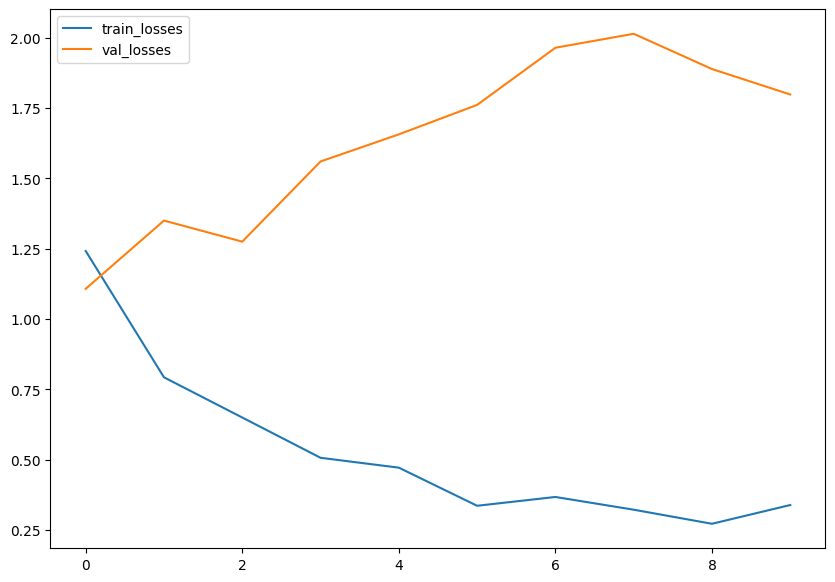

In [ ]:
plt.figure(figsize=(10, 7))
plt.plot(results_2_C0_C1_df['train_losses'], label='train_losses')
plt.plot(results_2_C0_C1_df['val_losses'], label='val_losses')
plt.legend()
plt.show()

In [24]:
model_2.load_state_dict(torch.load("best_model_2.pth"))
model_2.eval()
all_preds = []
all_targets = []
with torch.no_grad():
        for data, mask, target in test_loader:
            data = data.to(device)
            mask = mask.to(device)
            target = target.to(device)
            output = model_2(data, mask)
            preds = torch.argmax(output, dim=1)
            loss = torch.nn.CrossEntropyLoss()(output, target)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(target.cpu().numpy())
accuracy = accuracy_score(all_targets, all_preds)
multiclass_f1 = torchmetrics.classification.MulticlassF1Score(4, average='macro')
f1_score = multiclass_f1(torch.tensor(all_preds), torch.tensor(all_targets)).item()
print(f'Accuracy: {accuracy:.4f}, F1-Score: {f1_score:.4f}, loss: {loss:.4f}') 
     

Accuracy: 0.3418, F1-Score: 0.2690, loss: 1.4795


## Set Transformers

In [12]:
class SetTransformer(nn.Module):
    def __init__(self, num_features, embedding_dim, latent_dim, num_heads, output_dim):
        super().__init__()

        self.feature_embeddings = nn.Embedding(num_features, embedding_dim)
        self.input_projection = nn.Linear(embedding_dim+1, latent_dim)
        self.attention = nn.MultiheadAttention(embed_dim=latent_dim, num_heads=num_heads, batch_first=True)
        self.ffn = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),
            nn.ReLU(),
            nn.Linear(latent_dim, latent_dim)
        )
        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),
            nn.ReLU(),
            nn.Linear(latent_dim, output_dim)
        )
    def forward(self, x, mask):
        B, F = x.shape
        feature_ids = torch.arange(F, device=x.device)
        feature_ids = feature_ids.unsqueeze(0).expand(B,F)
        embeddings = self.feature_embeddings(feature_ids)
        values = x.unsqueeze(-1)
        elements = torch.cat([embeddings,values], dim=-1)
        elements = self.input_projection(elements)
        elements = torch.relu(elements)
        attention_mask = mask == 0
        attended, _ = self.attention(elements, elements, elements, key_padding_mask=attention_mask)
        elements = elements + attended 
        elements = elements + self.ffn(elements)
        elements = elements * mask.unsqueeze(-1)
        z = elements.sum(dim=1)
        logits = self.classifier(z)
        return logits

In [ ]:
def train_settransformer(train_loader, test_loader, model, criterion, optimizer, EPOCHS, checkpoint_path):
    best_loss = float('inf')
    accuracies = []
    train_losses = []
    val_losses = []
    f1_scores = []
    for epochs in range(EPOCHS):
        # Training loop
        model.train()
        for data, mask, target in train_loader:
            data = data.to(device)
            mask = mask.to(device)
            target = target.to(device)
            optimizer.zero_grad()
            output = model(data, mask)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()
        train_losses.append(loss.detach().cpu().numpy())
        # Evaluation
        model.eval()
        all_preds = []
        all_targets = []
        with torch.no_grad():
            for data, mask, target in test_loader:
                data = data.to(device)
                mask = mask.to(device)
                target = target.to(device)
                output = model(data, mask)
                preds = torch.argmax(output, dim=1)
                val_loss = criterion(output, target)
                all_preds.extend(preds.cpu().numpy())
                all_targets.extend(target.cpu().numpy())
        if val_loss.item() < best_loss:
            best_loss = val_loss.item()
            best_accuracy = accuracy_score(all_targets, all_preds)
            multiclass_f1 = torchmetrics.classification.MulticlassF1Score(4, average='macro')
            best_f1_score = multiclass_f1(torch.tensor(all_preds), torch.tensor(all_targets)).item()
            torch.save(model.state_dict(), checkpoint_path)  # Save the best model
            print(f"Best model saved with validation loss: {best_loss:.4f}")
        accuracy = accuracy_score(all_targets, all_preds)
        multiclass_f1 = torchmetrics.classification.MulticlassF1Score(4, average='macro')
        f1_score = multiclass_f1(torch.tensor(all_preds), torch.tensor(all_targets)).item()
        accuracies.append(accuracy)
        f1_scores.append(f1_score)
        val_losses.append(val_loss.detach().cpu().numpy())
        print(f'Epoch {epochs+1}/{EPOCHS}, train_loss: {loss:.4f}, val_loss: {val_loss:.4f}, Accuracy: {accuracy:.4f}, F1-Score: {f1_score:.4f}') 
    results = {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "accuracies": accuracies,
        "f1_scores": f1_scores
    }
    return results, best_accuracy, best_f1_score

In [ ]:
NUM_FEATURES = X_train.shape[1]
EMBEDDING_DIM = 16
LATENT_DIM = 64
NUM_HEADS = 4
OUTPUT_DIM = len(np.unique(y_train))
LEARNING_RATE = 1e-4
EPOCHS = 10

model_3 = SetTransformer(
    num_features = NUM_FEATURES,
    embedding_dim=EMBEDDING_DIM,
    latent_dim=LATENT_DIM,
    num_heads = NUM_HEADS,
    output_dim = OUTPUT_DIM
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_3.parameters(), lr=LEARNING_RATE)


train_loader, test_loader = create_deepset_dataloaders(X_train, X_test, y_train, y_test, C0, C1, batch_size=64)
results_3_C0_C1 = train_settransformer(train_loader, test_loader, model_3, criterion, optimizer, EPOCHS, "best_model_3_C0_C1.pth")

Best model saved with validation loss: 1.9805
Epoch 1/10, train_loss: 1.5940, val_loss: 1.9805, Accuracy: 0.2797, F1-Score: 0.1590
Best model saved with validation loss: 1.8286
Epoch 2/10, train_loss: 1.1477, val_loss: 1.8286, Accuracy: 0.2649, F1-Score: 0.1433
Epoch 3/10, train_loss: 1.0695, val_loss: 1.8380, Accuracy: 0.3044, F1-Score: 0.1635
Best model saved with validation loss: 1.8099
Epoch 4/10, train_loss: 1.3462, val_loss: 1.8099, Accuracy: 0.3137, F1-Score: 0.1586
Epoch 5/10, train_loss: 1.3085, val_loss: 2.0083, Accuracy: 0.2517, F1-Score: 0.1389
Epoch 6/10, train_loss: 1.1386, val_loss: 1.8265, Accuracy: 0.3613, F1-Score: 0.2307
Epoch 7/10, train_loss: 1.5354, val_loss: 1.8449, Accuracy: 0.3570, F1-Score: 0.2484
Epoch 8/10, train_loss: 1.0121, val_loss: 1.8835, Accuracy: 0.3602, F1-Score: 0.2259
Epoch 9/10, train_loss: 1.0117, val_loss: 1.9136, Accuracy: 0.4194, F1-Score: 0.2720
Epoch 10/10, train_loss: 1.1638, val_loss: 2.0511, Accuracy: 0.3642, F1-Score: 0.2281


In [18]:
results_3_C0_C1_df = pd.DataFrame(results_3_C0_C1)
results_3_C0_C1_df.to_csv('results_3_C0_C1_df.csv')